# Online: conformal test martingales and online prediction sets under label, domain and device shift

**Streams** (a new draw of every part for every stream; the methods never use the change point):
- **after the change**: a random sample of up to 600 images of the test split, an external set or the corrupted test split, with **their own class frequencies** $q_{\text{post}}$;
- **calibration set**: 16·C train images with a class mix $q$ (at least one per class, never more images of a class than the train split has): the only labels; the ND reference of the martingale, the calibration of the online sets and the confusion matrix of $\hat q$;
- **first images of the stream**: other train images with the same mix $q$, the largest such subsample up to 200 (streams with fewer than 50 are skipped);
- $q = q_{\text{post}}$ (**no label shift**, **domain shift**, **device shift**) or a Dirichlet draw with $\mathrm{KL}(q \Vert q_{\text{post}})$ = KL (**label shift**, KL = 0.1, 0.25, 0.5, 0.8, 1; capped at $0.9 \ln C$).

**Class mix** $\hat q_t$ after every image: BBSE soft on the exponential moving average (λ = 1/50) of the FCA soft labels (FCA with the calibration set as support), with the in-sample confusion matrix and $\mu_0$ of the calibration set.

**Martingale** (one per stream, Simple Jumper, capital 1 at the first image, alarm when $M_t \ge 1/\alpha$): conformity = cosine similarity to the nearest calibration image; each image ranked among all the previous images of the stream.
- **unweighted**: all weights 1;
- **$w_{online}$**: previous image $i$ weighted $w_i(t) = \sum_y p(y \mid x_i)\, \frac{\hat q_t(y) + \varepsilon}{\hat q_i(y) + \varepsilon}$, ε = 0.05: the class mix now over the mix estimated when $i$ arrived (the same rule for every image; ε smooths the ratio of two estimates near 0);
- **$w_{oracle}$** (reference: true labels and change point): $w_i(t) = q^*_t(y_i) / q^*_i(y_i)$, with the true mix $q^* = q_{\text{cal}}$ before the change and $q_{\text{post}}$ after it.

**Online prediction sets** (calibrated on the 16·C images): **FCP**, **FCP + $w_{online}$** (label weights $\hat q_t / q_{\text{cal}}$ of each image) and **FCP + $w_{oracle}$** (label weights $q^*_t / q_{\text{cal}}$: 1 before the change, $q_{\text{post}} / q_{\text{cal}}$ after it; knows the change point); moving average of the last 50 images of the coverage and the average class set size.

In [3]:
import sys, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, os.path.abspath('../'))  # project root
from utils.embedding_datasets import load_dataset, load_external_test_set, EXTERNAL_TEST_SETS
from utils.progress import status, hms
from conformal.conformal_prediction import fca_sets
from conformal.metrics import moving_window_counts, pooled_metrics
from conformal.online import stream_seed, build_stream, stream_pvalues, oracle_label_weights, simple_jumper

DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'local_data', 'embeddings'))
RESULTS = 'results/online_streams.csv'          # per stream image: log10 M of both martingales, covered / set size of both set methods
FIG_DIR = 'results/figures'
os.makedirs(FIG_DIR, exist_ok=True)

REPS, PRE, POST = 100, 200, 600
EPS = 0.05                                    # smoothing of the weight ratio (q̂_t + EPS) / (q̂_i + EPS); larger = more conservative
J, SHOTS, EMA_LAMBDA, ALPHA, CP_ALPHA, MA_WINDOW, MIN_STREAMS = 0.01, 16, 1 / 50, 0.01, 0.10, 50, 0.5
KLS = [0.1, 0.25, 0.5, 0.8, 1.0]
DEVICE = ['blur L1', 'blur L3', 'noise L1', 'noise L3']
DATASETS = ['CheXpert5x200', 'nihlt', 'covid', 'NCT', 'SICAPv2', 'Skin', 'MESSIDOR', 'FIVES', 'MMAC']
EXTERNAL = ['ZURICH', 'GERTYCH', 'DeepDRiD']
SHIFTS = ['no label shift'] + [f'label shift (KL = {kl:g})' for kl in KLS] + ['domain shift'] + DEVICE
CASES = [(n, s) for s in SHIFTS if s != 'domain shift' for n in DATASETS] + [(e, 'domain shift') for e in EXTERNAL]
WEIGHTINGS = ['unweighted', 'w_online', 'w_oracle']
SET_METHODS = ['fcp', 'fcp_w', 'fcp_o']
SHOW = {'unweighted': 'unweighted', 'w_online': '$w_{online}$ (same rule for every image)', 'w_oracle': '$w_{oracle}$ (true labels, change point)',
        'fcp': 'FCP', 'fcp_w': 'FCP + $w_{online}$', 'fcp_o': 'FCP + $w_{oracle}$'}
STYLE = {'unweighted': ('#0072B2', '-'), 'w_online': ('#D55E00', '--'), 'w_oracle': ('#000000', ':'),
         'fcp': ('#0072B2', '-'), 'fcp_w': ('#D55E00', '--'), 'fcp_o': ('#000000', ':')}
THR = np.log10(1 / ALPHA)

DATA, POOL = {}, {}           # POOL[case, shift] = (x, y) of the images after the change
for name in DATASETS:
    d = load_dataset(name, DATA_DIR)
    d['p_train'] = np.bincount(d['y_train'], minlength=d['n_classes']) / len(d['y_train'])
    DATA[name] = d
    for s in SHIFTS[:-5]:
        POOL[name, s] = (d['x_test'], d['y_test'])
    for s in DEVICE:
        c, l = s.split(' L')
        POOL[name, s] = (load_dataset(name, os.path.join(DATA_DIR, f'{c}_L{l}'))['x_test'], d['y_test'])
for e in EXTERNAL:
    x, y, _, _ = load_external_test_set(e, DATA_DIR)
    POOL[e, 'domain shift'] = (x, y)

# 1 · Run

Saved after every case to `RESULTS`; a re-run computes only the missing streams. Seeds: stream `stream_seed(case, shift, rep)`, p-values `1000·rep + 11`.

In [4]:
if os.path.exists(RESULTS) and 'logM_w_oracle' not in pd.read_csv(RESULTS, nrows=0).columns:
    raise RuntimeError(f'{RESULTS} has no oracle columns: move it away (e.g. to results/online_streams_no_oracle.csv) and run again')
done = set(map(tuple, pd.read_csv(RESULTS, usecols=['case', 'shift', 'rep']).drop_duplicates().values)) if os.path.exists(RESULTS) else set()
T0 = time.time()
for case, shift in CASES:
    todo = [r for r in range(REPS) if (case, shift, r) not in done]
    rows = []
    src = EXTERNAL_TEST_SETS[case]['source'] if shift == 'domain shift' else case
    d = DATA[src]
    for k, rep in enumerate(todo, start=1):
        status(f'{case:14s} {shift:24s} stream {k}/{len(todo)}  [{hms(time.time() - T0)}]')
        kl = float(shift.split('= ')[1][:-1]) if shift.startswith('label') else None
        st = build_stream(d, stream_seed((DATASETS + EXTERNAL).index(case), 60 + SHIFTS.index(shift), rep), *POOL[case, shift],
                         kl=kl, shots=SHOTS, pre=PRE, post=POST)
        if st is None:
            continue
        P, R = stream_pvalues(d, st, seed=1000 * rep + 11, lam=EMA_LAMBDA, eps=EPS)
        x_cal, y_cal, y, M = d['x_train'][st['cal']], d['y_train'][st['cal']], st['y'], len(st['y'])
        sets = {'fcp': fca_sets(x_cal, y_cal, st['x'], d['text_protos'], d['logit_scale'], alpha=CP_ALPHA),
                'fcp_w': fca_sets(x_cal, y_cal, st['x'], d['text_protos'], d['logit_scale'], alpha=CP_ALPHA, weights=R),
                'fcp_o': fca_sets(x_cal, y_cal, st['x'], d['text_protos'], d['logit_scale'], alpha=CP_ALPHA, weights=oracle_label_weights(d, st))}
        row = {'case': case, 'shift': shift, 'rep': rep, 'source': src, 'C': d['n_classes'], 'n_cal': len(st['cal']), 'n_pre': st['change'],
               't': np.arange(M) - st['change'], 'y': y,
               **{f'logM_{w}': simple_jumper(P[w], J).round(4) for w in WEIGHTINGS},
               **{f'covered_{m}': S[np.arange(M), y].astype(int) for m, S in sets.items()},
               **{f'size_{m}': S.sum(1) for m, S in sets.items()}}
        rows.append(pd.DataFrame(row))
    if rows:
        pd.concat(rows).to_csv(RESULTS, mode='a', header=not os.path.exists(RESULTS), index=False)
        status(f'{case:14s} {shift:24s} {len(todo)} streams  [{hms(time.time() - T0)}]'); print(' -> done!', flush=True)
df = pd.read_csv(RESULTS)
df = df[df['rep'] < REPS]
print(f"{df.groupby(['case', 'shift', 'rep']).ngroups} streams")

9300 streams


# 2 · Alarms at α = 1 %

Alarm = first image with $M_t \ge 1/\alpha = 100$. **False alarm %**: alarm before the change (the first train images); **alarm % after the change** (wanted under domain / device shift, not under label shift); **delay**: images from the change to the alarm (mean over the alarms after it).

In [5]:
keys = ['case', 'shift', 'rep']
streams = df[keys].drop_duplicates()
rows = []
for w in WEIGHTINGS:
    hit = df.loc[df[f'logM_{w}'] >= THR].groupby(keys)['t'].min().reindex(pd.MultiIndex.from_frame(streams)).rename('alarm').reset_index()
    for s in SHIFTS:
        q = hit[hit['shift'] == s]
        after = q['alarm'] >= 0
        rows.append({'weighting': w, 'shift': s, 'streams': len(q), 'alarm % after change': 100 * after.mean(),
                     'mean delay': (q.loc[after, 'alarm'] + 1).mean(), 'false alarm %': 100 * (q['alarm'] < 0).mean()})
tab = pd.DataFrame(rows)
tab.round(2).to_csv('results/online_alarms_alpha_1pct.csv', index=False)
for col in ['alarm % after change', 'mean delay', 'false alarm %']:
    print(col); display(tab.pivot_table(index='weighting', columns='shift', values=col).reindex(columns=SHIFTS).round(1))

alarm % after change


shift,no label shift,label shift (KL = 0.1),label shift (KL = 0.25),label shift (KL = 0.5),label shift (KL = 0.8),label shift (KL = 1),domain shift,blur L1,blur L3,noise L1,noise L3
weighting,,,,,,,,,,,
unweighted,9.2,12.7,19.6,42.0,60.3,65.0,99.3,36.2,77.8,81.9,84.6
w_online,8.7,8.8,12.2,27.7,43.8,49.0,99.7,34.9,77.7,79.6,83.8
w_oracle,9.1,7.9,6.8,14.8,24.0,26.7,99.3,36.4,77.8,81.8,84.6


mean delay


shift,no label shift,label shift (KL = 0.1),label shift (KL = 0.25),label shift (KL = 0.5),label shift (KL = 0.8),label shift (KL = 1),domain shift,blur L1,blur L3,noise L1,noise L3
weighting,,,,,,,,,,,
unweighted,174.3,149.9,147.5,114.6,88.8,74.9,22.7,106.7,32.2,86.0,37.4
w_online,166.1,156.1,146.2,108.2,90.6,81.9,22.8,105.9,32.8,87.7,37.6
w_oracle,173.0,205.1,190.9,157.7,127.1,122.2,22.7,107.2,32.2,85.8,37.4


false alarm %


shift,no label shift,label shift (KL = 0.1),label shift (KL = 0.25),label shift (KL = 0.5),label shift (KL = 0.8),label shift (KL = 1),domain shift,blur L1,blur L3,noise L1,noise L3
weighting,,,,,,,,,,,
unweighted,0.8,0.4,0.6,0.1,0.2,0.1,0.7,0.1,0.2,0.1,0.4
w_online,0.7,0.2,0.4,0.4,0.7,0.7,0.3,0.2,0.1,0.1,0.2
w_oracle,0.8,0.4,0.6,0.1,0.2,0.1,0.7,0.1,0.2,0.1,0.4


# 3 · Martingales and online sets, per shift case

One figure per shift case, over all its streams: the mean $\log_{10} M_t$ (band: interquartile range; dotted: $\log_{10}(1/\alpha)$) of the three martingales, and the moving average of the last 50 images of the coverage and the average class set size of FCP, FCP + $w_{online}$ and FCP + $w_{oracle}$. Saved as `results/figures/online_<shift>.png`; curves in `results/online_martingale_curves.csv` and `results/online_moving_average.csv` (with the number of streams at every $t$).

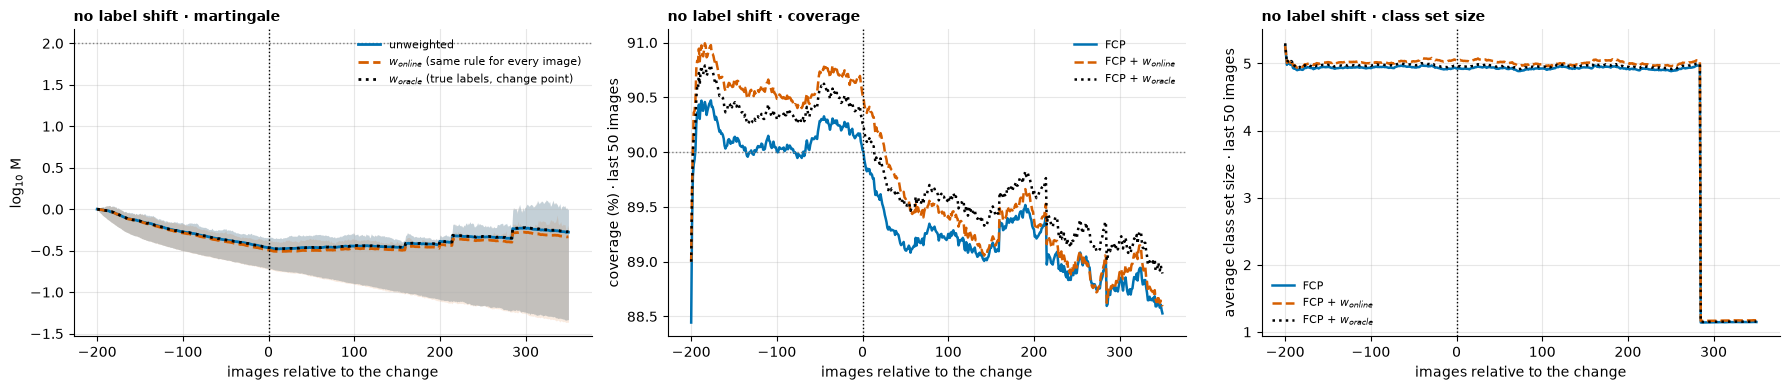

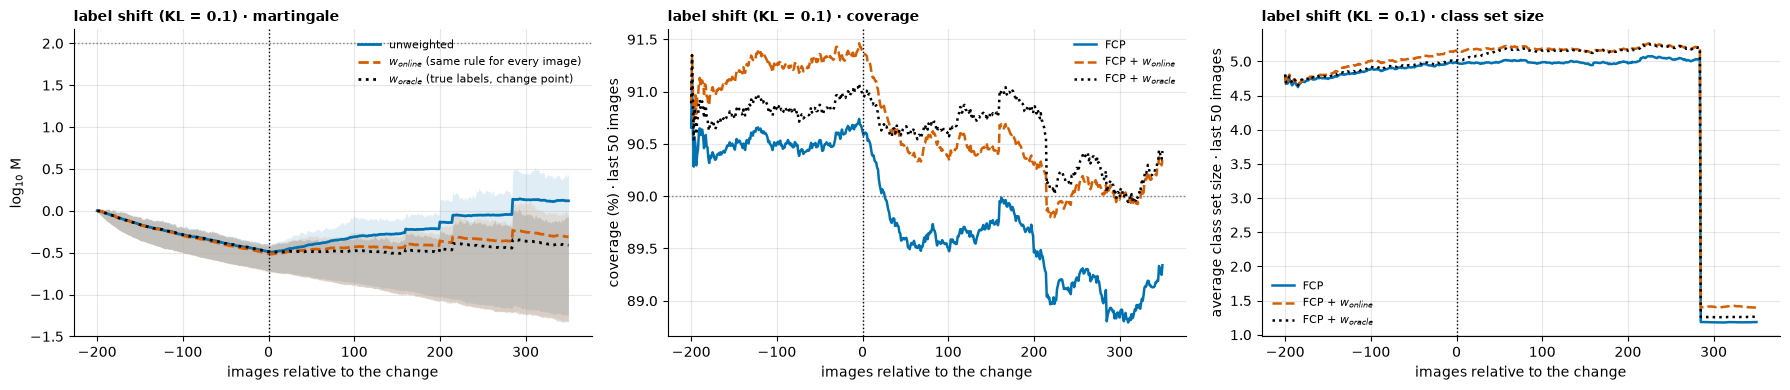

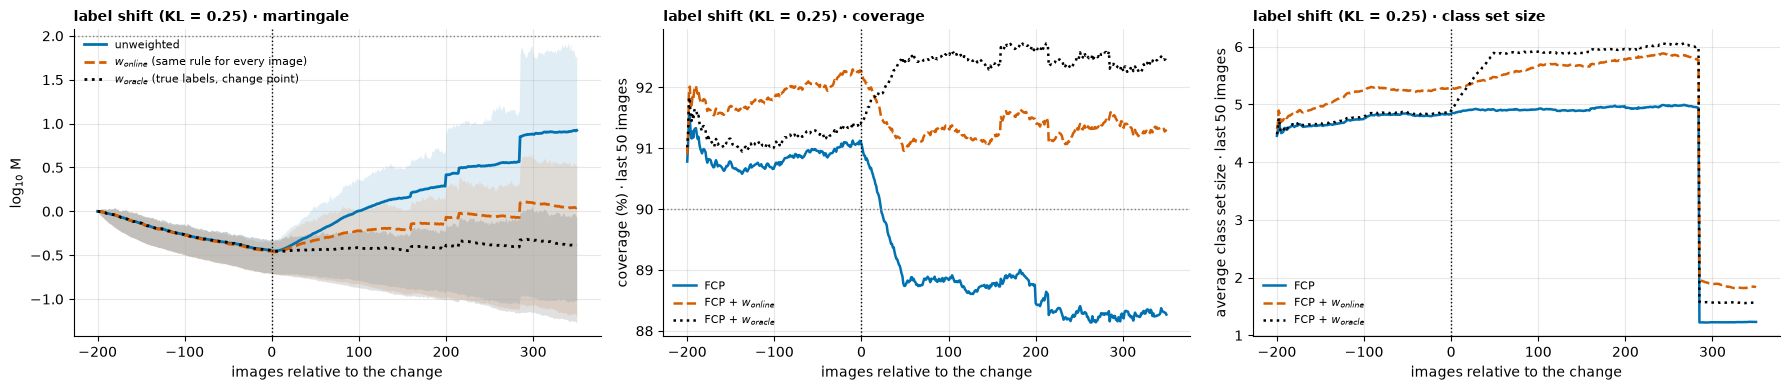

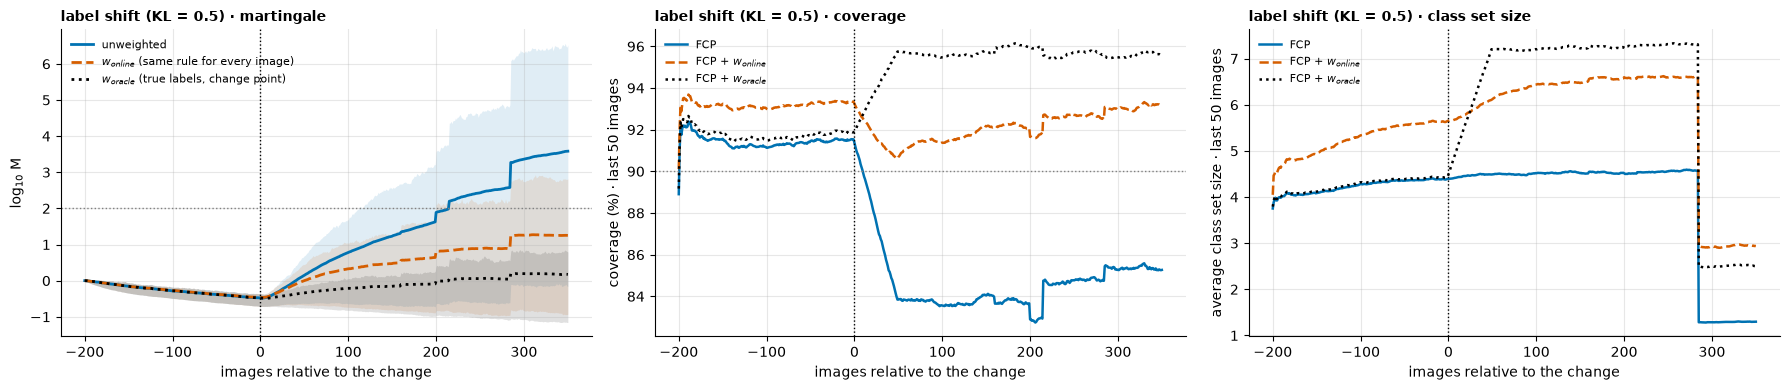

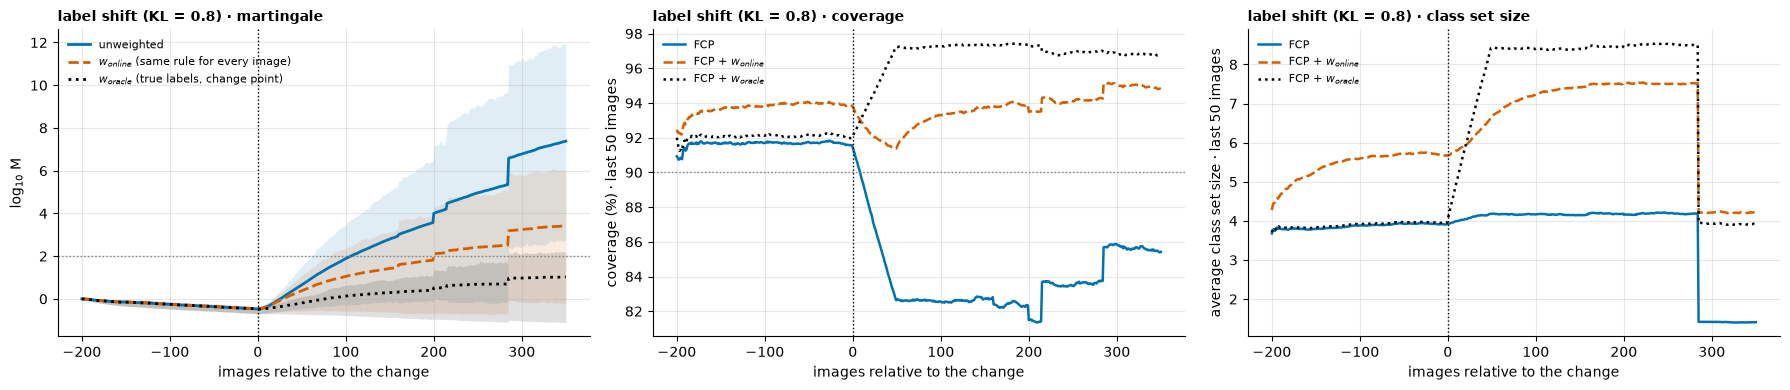

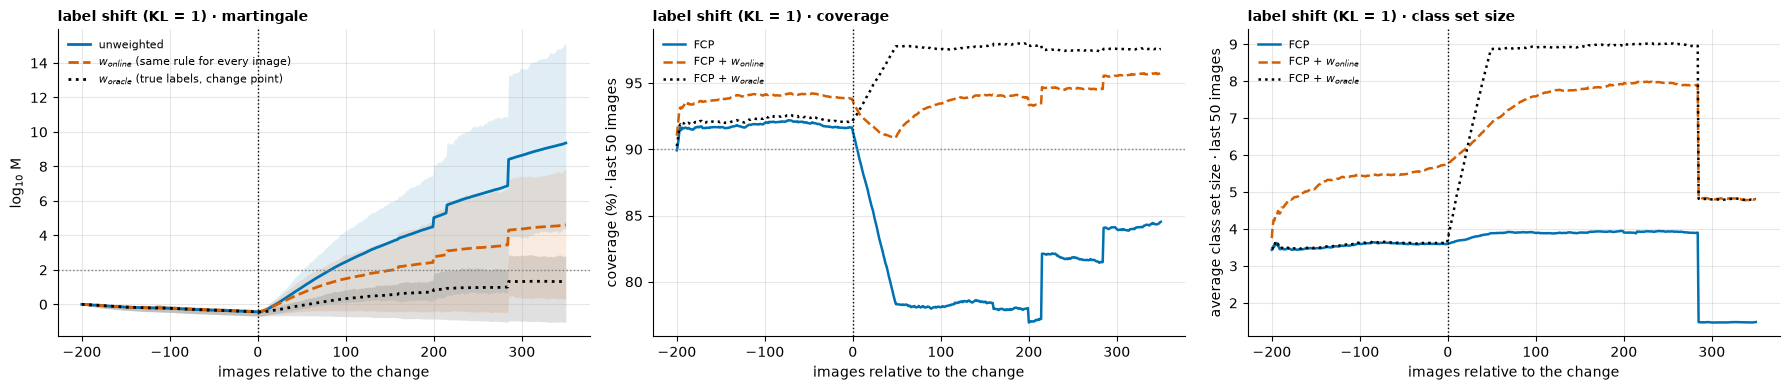

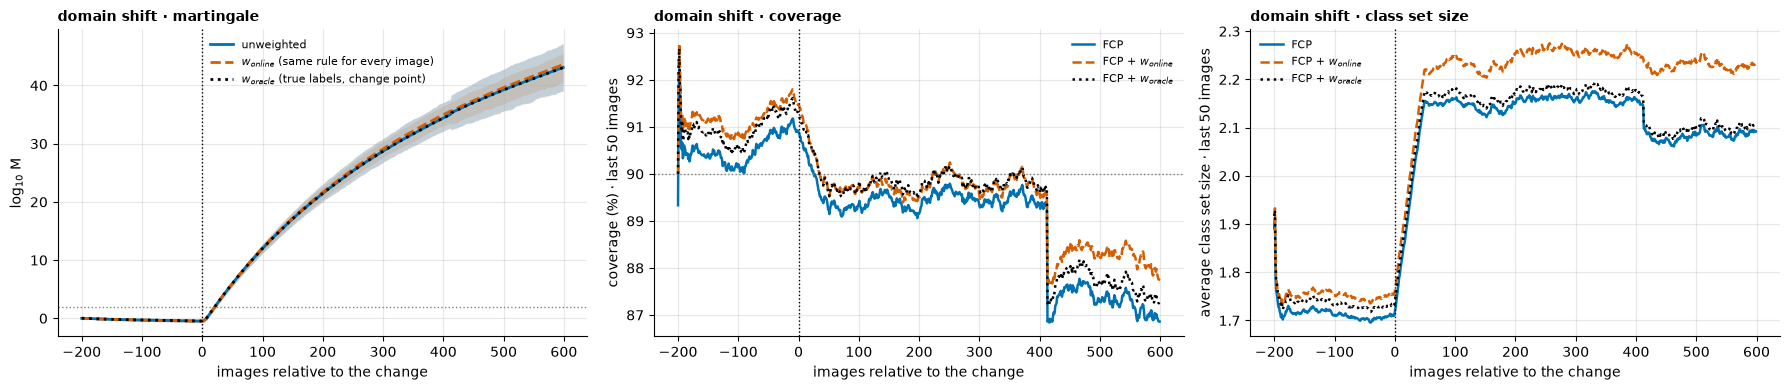

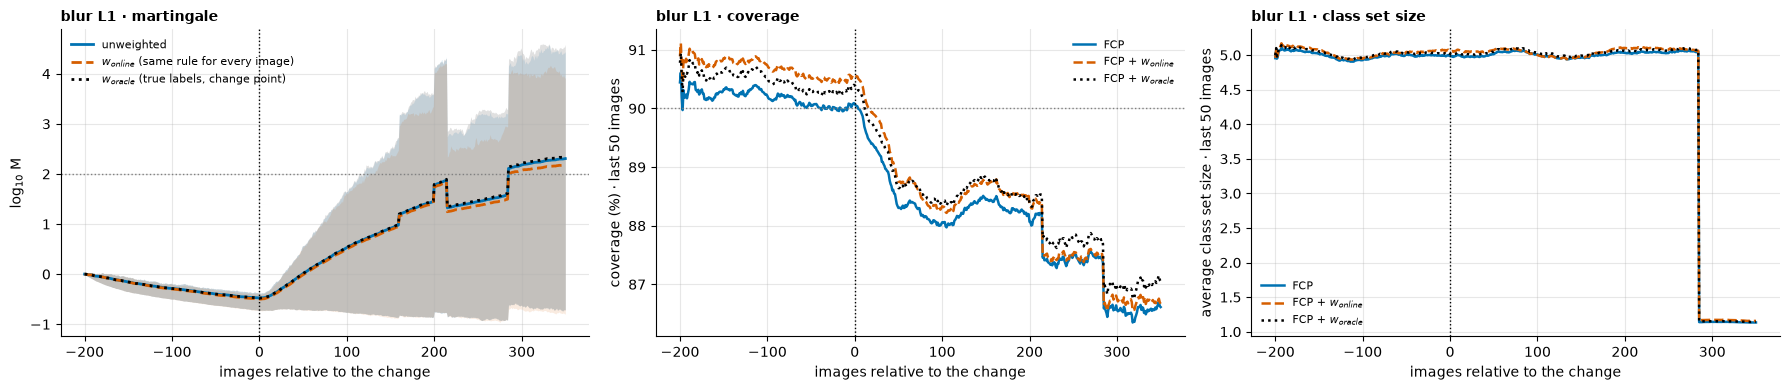

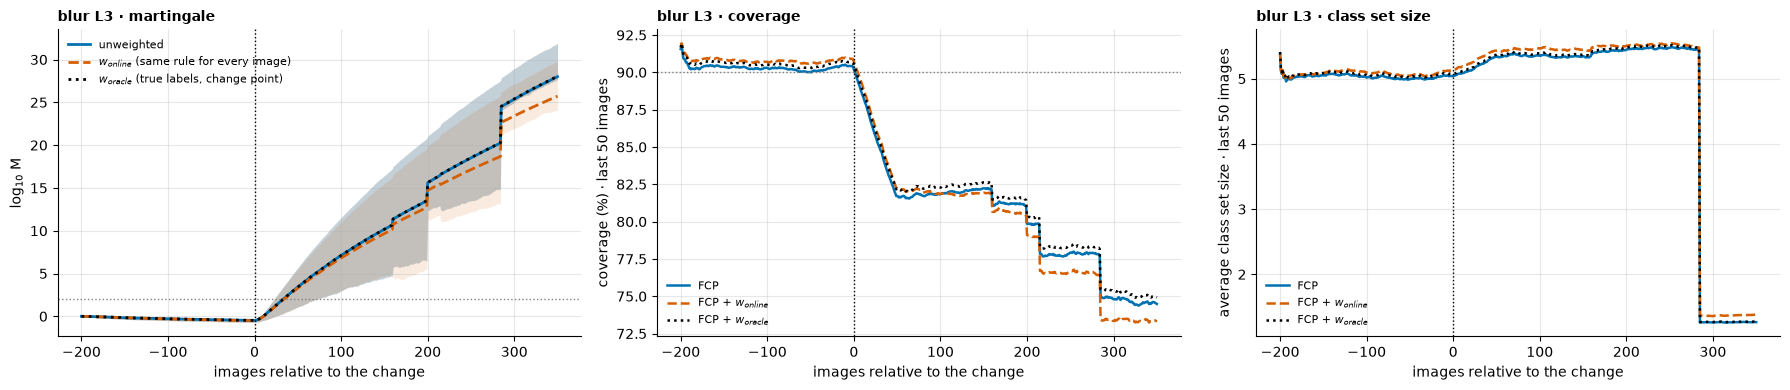

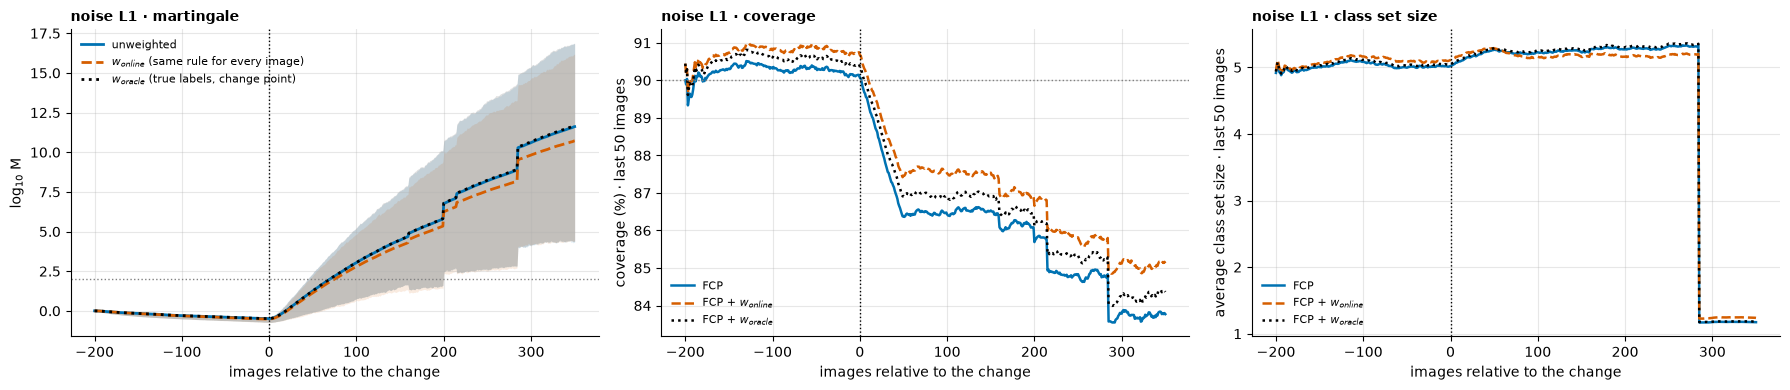

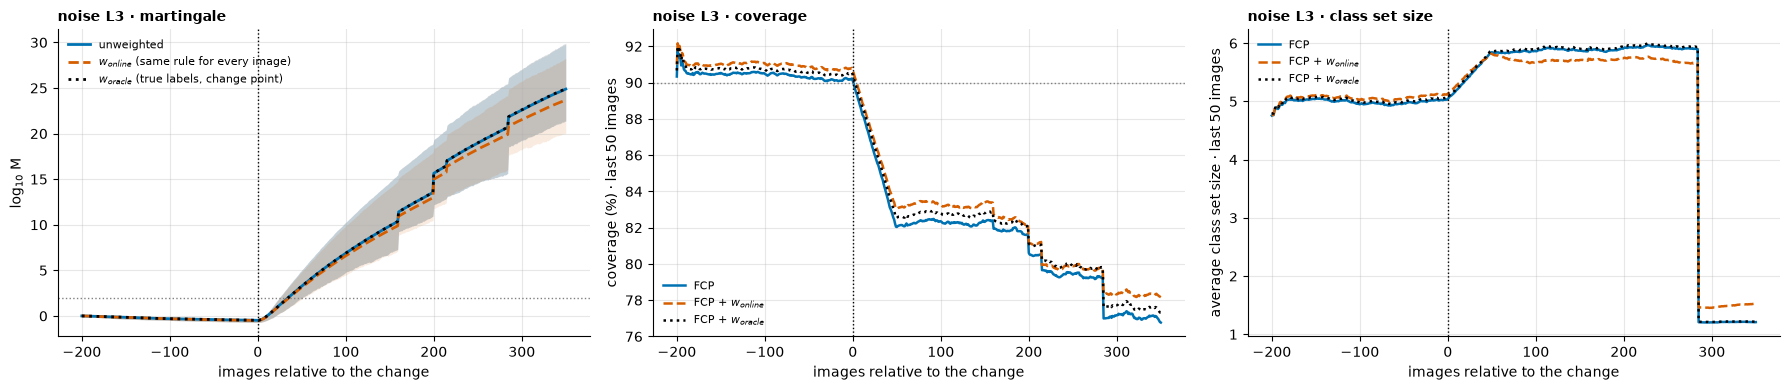

In [6]:
T_AX = np.arange(-PRE, POST)
mart, acc = [], {}
for w in WEIGHTINGS:                                    # martingale paths
    g = df.groupby(['shift', 't'])[f'logM_{w}']
    mart.append(pd.DataFrame({'mean': g.mean(), 'q25': g.quantile(0.25), 'q75': g.quantile(0.75), 'streams': g.count()})
                .reset_index().assign(weighting=w))
mart = pd.concat(mart)
for (c, s, r), g in df.groupby(keys, sort=False):     # moving averages, pooled over the streams
    t = g['t'].to_numpy(); k = (t >= -PRE) & (t < POST); C = int(g['C'].iat[0]); y = g['y'].to_numpy()
    for m in SET_METHODS:
        n, cov, size, n_all = moving_window_counts(y, g[f'covered_{m}'].to_numpy(), g[f'size_{m}'].to_numpy(), C, MA_WINDOW)
        idx = t[k] + PRE
        a = acc.setdefault((s, m), [np.zeros((len(T_AX), 64)) for _ in range(3)] + [np.zeros(len(T_AX)), np.zeros(len(T_AX))])
        a[0][idx, :C] += n[k]; a[1][idx, :C] += cov[k]; a[2][idx, :C] += size[k]; a[3][idx] += n_all[k]; a[4][idx] += 1
ma = pd.DataFrame([{'shift': s, 'method': m, 't': int(T_AX[j]), 'streams': int(a[4][j]),
                    **pooled_metrics(a[0][j], a[1][j], a[2][j], a[3][j], CP_ALPHA)}
                   for (s, m), a in acc.items() for j in range(len(T_AX)) if a[0][j].sum() > 0])
mart.round(4).to_csv('results/online_martingale_curves.csv', index=False)
ma.round(3).to_csv('results/online_moving_average.csv', index=False)

cut = lambda q: q[q['streams'] >= MIN_STREAMS * q['streams'].max()]
for s in SHIFTS:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    for w in WEIGHTINGS:
        q = cut(mart[(mart['shift'] == s) & (mart['weighting'] == w)]); c, ls = STYLE[w]
        axes[0].plot(q['t'], q['mean'], color=c, ls=ls, lw=2, label=SHOW[w])
        axes[0].fill_between(q['t'], q['q25'], q['q75'], color=c, alpha=0.12, lw=0)
    axes[0].axhline(THR, color='gray', ls=':', lw=1); axes[0].set_ylabel('log$_{10}$ M')
    for ax, col, lab in [(axes[1], 'coverage', 'coverage (%)'), (axes[2], 'class_set_size', 'average class set size')]:
        for m in SET_METHODS:
            q = cut(ma[(ma['shift'] == s) & (ma['method'] == m)]); c, ls = STYLE[m]
            ax.plot(q['t'], q[col], color=c, ls=ls, lw=1.8, label=SHOW[m])
        if col == 'coverage': ax.axhline(100 * (1 - CP_ALPHA), color='gray', ls=':', lw=1)
        ax.set_ylabel(f'{lab} · last {MA_WINDOW} images')
    for ax, title in zip(axes, ['martingale', 'coverage', 'class set size']):
        ax.axvline(0, color='black', ls=':', lw=1); ax.set_xlabel('images relative to the change')
        ax.set_title(f'{s} · {title}', loc='left', fontsize=10, fontweight='bold')
        ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False); ax.legend(fontsize=8, frameon=False)
    plt.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f"online_{s.replace(' ', '_').replace('(', '').replace(')', '').replace('=_', '')}.png"),
                dpi=200, bbox_inches='tight')
    plt.show()

# 4 · Per dataset: alarms and sizes

Alarm rate after the change per dataset (domain shift: per external set) for both martingales; size of the calibration set, of the first part of the stream and of the part after the change (mean ± std, number of streams).

In [7]:
rows_order = DATASETS + EXTERNAL
short = lambda t: t.rename(columns=lambda c: c.replace('label shift ', ''))
for w in WEIGHTINGS:
    first = df.loc[df[f'logM_{w}'] >= THR].groupby(keys)['t'].min().reindex(pd.MultiIndex.from_frame(streams))
    alarm = (100 * (first >= 0)).groupby(level=['case', 'shift']).mean().unstack('shift').reindex(index=rows_order, columns=SHIFTS)
    alarm.round(2).to_csv(f'results/online_alarm_rate_per_dataset_{w}.csv')
    print(f'alarm rate after the change (%) · {SHOW[w]}'); display(short(alarm.dropna(how='all').round(1)))
per_stream = df.groupby(keys).agg(n_cal=('n_cal', 'first'), n_pre=('n_pre', 'first'), n_post=('t', lambda t: int((t >= 0).sum())))
for col, lab in [('n_cal', 'calibration images'), ('n_pre', 'images before the change'), ('n_post', 'images after the change')]:
    g = per_stream[col].groupby(level=['case', 'shift'])
    t = (g.mean().round(0).astype(int).astype(str) + ' ± ' + g.std().fillna(0).round(0).astype(int).astype(str)
         + ' (' + g.size().astype(str) + ')').unstack('shift').reindex(index=rows_order, columns=SHIFTS)
    t.to_csv(f'results/online_{col}_per_dataset.csv')
    print(f'{lab} per stream: mean ± std (streams)'); display(short(t.dropna(how='all').fillna('–')))


alarm rate after the change (%) · unweighted


shift,no label shift,(KL = 0.1),(KL = 0.25),(KL = 0.5),(KL = 0.8),(KL = 1),domain shift,blur L1,blur L3,noise L1,noise L3
case,,,,,,,,,,,
CheXpert5x200,1.0,0.0,0.0,9.0,20.0,30.0,NaN,0.0,0.0,0.0,0.0
nihlt,0.0,1.0,0.0,1.0,2.0,3.0,NaN,0.0,1.0,62.0,100.0
covid,0.0,6.0,21.0,60.0,68.0,79.0,NaN,2.0,100.0,100.0,99.0
NCT,76.0,86.0,92.0,100.0,100.0,100.0,NaN,100.0,100.0,100.0,100.0
SICAPv2,4.0,6.0,21.0,57.0,93.0,87.0,NaN,40.0,100.0,85.0,100.0
Skin,2.0,9.0,21.0,71.0,92.0,93.0,NaN,3.0,100.0,98.0,100.0
MESSIDOR,0.0,1.0,1.0,12.0,53.0,74.0,NaN,81.0,100.0,100.0,99.0
FIVES,0.0,2.0,7.0,36.0,60.0,74.0,NaN,0.0,100.0,92.0,64.0
MMAC,0.0,3.0,13.0,32.0,55.0,45.0,NaN,100.0,99.0,100.0,99.0


alarm rate after the change (%) · $w_{online}$ (same rule for every image)


shift,no label shift,(KL = 0.1),(KL = 0.25),(KL = 0.5),(KL = 0.8),(KL = 1),domain shift,blur L1,blur L3,noise L1,noise L3
case,,,,,,,,,,,
CheXpert5x200,1.0,0.0,0.0,1.0,6.0,15.0,NaN,0.0,0.0,0.0,0.0
nihlt,0.0,1.0,1.0,1.0,1.0,0.0,NaN,0.0,0.0,54.0,100.0
covid,0.0,1.0,9.0,34.0,54.0,67.0,NaN,2.0,100.0,100.0,100.0
NCT,73.0,71.0,68.0,93.0,95.0,99.0,NaN,100.0,100.0,100.0,100.0
SICAPv2,4.0,1.0,18.0,41.0,92.0,86.0,NaN,43.0,100.0,83.0,100.0
Skin,0.0,3.0,8.0,33.0,72.0,78.0,NaN,0.0,100.0,98.0,100.0
MESSIDOR,0.0,0.0,2.0,6.0,7.0,24.0,NaN,68.0,100.0,100.0,99.0
FIVES,0.0,0.0,1.0,11.0,26.0,38.0,NaN,1.0,100.0,87.0,55.0
MMAC,0.0,2.0,3.0,29.0,41.0,34.0,NaN,100.0,99.0,94.0,100.0


alarm rate after the change (%) · $w_{oracle}$ (true labels, change point)


shift,no label shift,(KL = 0.1),(KL = 0.25),(KL = 0.5),(KL = 0.8),(KL = 1),domain shift,blur L1,blur L3,noise L1,noise L3
case,,,,,,,,,,,
CheXpert5x200,1.0,0.0,2.0,1.0,6.0,5.0,NaN,0.0,0.0,0.0,0.0
nihlt,0.0,1.0,0.0,2.0,4.0,5.0,NaN,0.0,1.0,62.0,100.0
covid,0.0,1.0,3.0,28.0,21.0,27.0,NaN,2.0,100.0,100.0,99.0
NCT,76.0,64.0,41.0,57.0,77.0,77.0,NaN,100.0,100.0,100.0,100.0
SICAPv2,3.0,1.0,11.0,14.0,38.0,22.0,NaN,40.0,100.0,85.0,100.0
Skin,2.0,2.0,4.0,15.0,38.0,53.0,NaN,3.0,100.0,98.0,100.0
MESSIDOR,0.0,1.0,0.0,5.0,2.0,8.0,NaN,83.0,100.0,100.0,99.0
FIVES,0.0,0.0,0.0,1.0,16.0,17.0,NaN,0.0,100.0,92.0,64.0
MMAC,0.0,1.0,0.0,10.0,14.0,26.0,NaN,100.0,99.0,99.0,99.0


... (2 outputs left out)

images before the change per stream: mean ± std (streams)


shift,no label shift,(KL = 0.1),(KL = 0.25),(KL = 0.5),(KL = 0.8),(KL = 1),domain shift,blur L1,blur L3,noise L1,noise L3
case,,,,,,,,,,,
CheXpert5x200,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),195 ± 9 (100),159 ± 26 (100),132 ± 17 (100),–,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100)
nihlt,200 ± 0 (100),189 ± 31 (100),186 ± 30 (100),179 ± 39 (100),189 ± 29 (100),182 ± 41 (100),–,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100)
covid,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),–,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100)
NCT,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),–,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100)
SICAPv2,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),–,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100)
Skin,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),–,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100)
MESSIDOR,200 ± 0 (100),200 ± 1 (100),195 ± 19 (100),195 ± 21 (100),184 ± 39 (100),191 ± 31 (100),–,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100)
FIVES,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),184 ± 15 (100),145 ± 13 (100),117 ± 4 (100),–,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100)
MMAC,200 ± 0 (100),191 ± 26 (100),189 ± 31 (100),187 ± 36 (100),183 ± 27 (100),183 ± 32 (100),–,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100)


images after the change per stream: mean ± std (streams)


shift,no label shift,(KL = 0.1),(KL = 0.25),(KL = 0.5),(KL = 0.8),(KL = 1),domain shift,blur L1,blur L3,noise L1,noise L3
case,,,,,,,,,,,
CheXpert5x200,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),–,200 ± 0 (100),200 ± 0 (100),200 ± 0 (100),200 ± 0 (100)
nihlt,285 ± 0 (100),285 ± 0 (100),285 ± 0 (100),285 ± 0 (100),285 ± 0 (100),285 ± 0 (100),–,285 ± 0 (100),285 ± 0 (100),285 ± 0 (100),285 ± 0 (100)
covid,600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),–,600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100)
NCT,600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),–,600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100)
SICAPv2,600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),–,600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100)
Skin,600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),–,600 ± 0 (100),600 ± 0 (100),600 ± 0 (100),600 ± 0 (100)
MESSIDOR,351 ± 0 (100),351 ± 0 (100),351 ± 0 (100),351 ± 0 (100),351 ± 0 (100),351 ± 0 (100),–,351 ± 0 (100),351 ± 0 (100),351 ± 0 (100),351 ± 0 (100)
FIVES,160 ± 0 (100),160 ± 0 (100),160 ± 0 (100),160 ± 0 (100),160 ± 0 (100),160 ± 0 (100),–,160 ± 0 (100),160 ± 0 (100),160 ± 0 (100),160 ± 0 (100)
MMAC,215 ± 0 (100),215 ± 0 (100),215 ± 0 (100),215 ± 0 (100),215 ± 0 (100),215 ± 0 (100),–,215 ± 0 (100),215 ± 0 (100),215 ± 0 (100),215 ± 0 (100)
